# Lab 3 — Millions of TVs, Who Is Watching?

Name: Feofila Donkohloa | Group: КМ-43

In [29]:
import kagglehub
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [30]:
DATA = kagglehub.dataset_download("shkarupylomaxim/adtech-lab1-tv-panel/versions/4")
programs = pd.read_parquet(f"{DATA}/programs.parquet")
viewings = pd.read_parquet(f"{DATA}/viewings.parquet")
daily_weights = pd.read_parquet(f"{DATA}/daily_weights.parquet")
viewer_attributes = pd.read_parquet(f"{DATA}/viewer_attributes.parquet")
attributes = pd.read_parquet(f"{DATA}/attributes.parquet")
acr_sessions = pd.read_parquet(f"{DATA}/acr_sessions.parquet")
hh_attributes = pd.read_parquet(f"{DATA}/hh_attributes.parquet")
reference_ratings = pd.read_parquet(f"{DATA}/reference_ratings.parquet")

Using Colab cache for faster access to the 'adtech-lab1-tv-panel' dataset.


##Task 1.1 — Five questions

| Feature | `acr_sessions` (Lab 3) | `viewings` (Lab 1) |
| --- | --- | --- |
| **Grain** | One continuous viewing session on one TV. | One viewing session by one person (or household). |
| **Key** | `session_id` | `viewing_id` |
| **Coverage** | Convenience sample of opted-in smart TVs. | Representative sample of the US TV population. |
| **Weight** | Unweighted (each TV counts once). | Weighted (`daily_weights` project to US population). |
| **Provenance** | ACR data from a TV manufacturer (e.g., LG). | A curated currency panel (e.g., Nielsen).

 |

The biggest difference: The biggest difference is Weight and Coverage / Grain. acr_sessions is a massive unweighted convenience sample of devices (TVs), meaning it has inherent biases based on who buys those TVs and opts in. viewings is a carefully recruited, representative, and weighted sample of people designed to reflect the entire population.

##Task 1.2 — Size and shape

In [31]:
if acr_sessions['start_utc'].dt.tz is None:
    acr_sessions['start_utc'] = acr_sessions['start_utc'].dt.tz_localize('UTC')
    acr_sessions['end_utc'] = acr_sessions['end_utc'].dt.tz_localize('UTC')

acr_sessions['start_et'] = acr_sessions['start_utc'].dt.tz_convert('US/Eastern')
acr_sessions['end_et'] = acr_sessions['end_utc'].dt.tz_convert('US/Eastern')

acr_sessions['broadcast_day'] = (acr_sessions['start_et'] - pd.Timedelta(hours=6)).dt.date

acr_sessions['duration_sec'] = (acr_sessions['end_utc'] - acr_sessions['start_utc']).dt.total_seconds()
acr_sessions['duration_hours'] = acr_sessions['duration_sec'] / 3600

valid_sessions = acr_sessions[acr_sessions['duration_sec'] >= 60].copy()

in_tab_tv_days = valid_sessions.groupby('broadcast_day')['tv_id'].nunique()
total_in_tab_tv_days = in_tab_tv_days.sum()

total_tvs = acr_sessions['tv_id'].nunique()
total_sessions = len(acr_sessions)
broadcast_days = acr_sessions['broadcast_day'].nunique()
avg_tvs_in_tab = in_tab_tv_days.mean()

total_hours_raw = acr_sessions['duration_hours'].sum()
total_hours_valid = valid_sessions['duration_hours'].sum()

hours_per_tv_day_raw = total_hours_raw / total_in_tab_tv_days
hours_per_tv_day_valid = total_hours_valid / total_in_tab_tv_days

sessions_dropped = total_sessions - len(valid_sessions)
share_dropped = (sessions_dropped / total_sessions) * 100

print(f"TVs: {total_tvs}")
print(f"Sessions: {total_sessions}")
print(f"Broadcast days: {broadcast_days}")
print(f"Average TVs in-tab per day: {avg_tvs_in_tab:.0f}")
print(f"Hours per TV per day, raw: {hours_per_tv_day_raw:.2f}")
print(f"Hours per TV per day, after edit rule: {hours_per_tv_day_valid:.2f}")
print(f"Share of sessions dropped: {share_dropped:.1f}")

TVs: 29940
Sessions: 6392981
Broadcast days: 14
Average TVs in-tab per day: 29074
Hours per TV per day, raw: 4.74
Hours per TV per day, after edit rule: 4.70
Share of sessions dropped: 29.9


## Task 1.3 — What the TV could not see

In [32]:
total_valid_hours = valid_sessions['duration_hours'].sum()

share_by_session_type = (valid_sessions.groupby('session_type')['duration_hours'].sum() / total_valid_hours).round(3)
print("Share of hours by session_type")
print(share_by_session_type.to_string(name=False))
print("\n")

share_by_input = (valid_sessions.groupby('input_source')['duration_hours'].sum() / total_valid_hours).round(3)
print("--- Share of hours by input_source ---")
print(share_by_input.to_string(name=False))
print("\n")

unknown_share_pct = (valid_sessions[valid_sessions['session_type'] == 'unknown']['duration_hours'].sum() / total_valid_hours) * 100
print(f"Share of TV-on hours unknown (%): {unknown_share_pct:.1f}")

Share of hours by session_type
session_type
app        0.257
dvr        0.025
live       0.322
unknown    0.396


--- Share of hours by input_source ---
input_source
antenna             0.086
built_in_app        0.307
cable_box           0.276
game_or_disc        0.024
satellite_box       0.076
streaming_device    0.231


Share of TV-on hours unknown (%): 39.6


Why a real feed may have more unknown: Real ACR systems rely on matching screen fingerprints against a limited reference library of live TV feeds. In the real world, there is a massive variety of un-fingerprinted content (niche channels, local programming, countless streaming platforms, YouTube). A synthetic dataset usually has a simplified ecosystem, so a real ACR feed will naturally fail to recognize a larger portion of what's on the screen.

Two kinds of viewing that end up unknown:

Video Games or Physical Media: Playing a console (PlayStation/Xbox) or watching a DVD/Blu-ray, which are not in any live TV reference library.

Unrecognized Streaming Apps / VOD: Watching Netflix, YouTube, or other on-demand streaming content that the ACR vendor is not actively tracking or finger-printing.

##Task 2.1 — Match

In [33]:
tv_ips = acr_sessions[['tv_id', 'hashed_ip']].drop_duplicates()
total_unique_tvs = len(tv_ips)

ip_hh_counts = hh_attributes.groupby('hashed_ip')['household_id'].nunique().reset_index()
ip_hh_counts.columns = ['hashed_ip', 'hh_count']

tv_match = tv_ips.merge(ip_hh_counts, on='hashed_ip', how='left')
tv_match['hh_count'] = tv_match['hh_count'].fillna(0)

matched_one = len(tv_match[tv_match['hh_count'] == 1])
shared_ip = len(tv_match[tv_match['hh_count'] > 1])
not_matched = len(tv_match[tv_match['hh_count'] == 0])

pct_matched_one = (matched_one / total_unique_tvs) * 100
pct_shared_ip = (shared_ip / total_unique_tvs) * 100
pct_not_matched = (not_matched / total_unique_tvs) * 100

print(f"Matched to one household (%): {pct_matched_one:.1f}")
print(f"Shared IP, unresolved (%): {pct_shared_ip:.1f}")
print(f"Not matched (%): {pct_not_matched:.1f}")

Matched to one household (%): 65.2
Shared IP, unresolved (%): 11.8
Not matched (%): 22.9


An IP address makes a weak key because it is often shared or dynamic. Multiple households can share a single IP address if they live in apartment buildings or use the same public/shared network (NAT). Furthermore, ISPs routinely rotate dynamic IP addresses, and the use of VPNs or mobile networks means an IP address does not reliably point to a single, stable physical household over time.

## Task 2.2 — Profile

In [34]:
print("daily_weights columns:", daily_weights.columns.tolist())
print("attributes columns:", attributes.columns.tolist())
print("viewer_attributes columns:", viewer_attributes.columns.tolist())
print("viewings columns:", viewings.columns.tolist())

daily_weights columns: ['respondent_id', 'resp_type', 'broadcast_date', 'weight']
attributes columns: ['attr_id', 'attr_group', 'attr_name', 'value_type', 'applies_to']
viewer_attributes columns: ['respondent_id', 'attr_id', 'value']
viewings columns: ['viewing_id', 'respondent_id', 'resp_type', 'guest_attr_ids', 'network_code', 'start_ts', 'end_ts', 'playback', 'weight']


In [35]:
print(attributes['attr_name'].unique().tolist())

['R: panel member (household member)', 'L: long-term visitor', 'S: short-term visitor (guest); id ends 81, 82, ... = guest button, not a stable person', 'H: household record (id ending 00)', 'Male', 'Female', 'Age in years', '2-5', '6-11', '12-17', '18-20', '21-24', '25-34', '35-49', '50-54', '55-64', '65+', 'Hispanic', 'White, non-Hispanic', 'Black, non-Hispanic', 'Asian, non-Hispanic', 'Other, non-Hispanic', 'Less than high school', 'High school graduate', 'Some college / associate', "Bachelor's degree or higher", 'Working full time (30+ h/week)', 'Working part time', 'Not working', 'Head of house', 'Lady of house', '1 person', '2 persons', '3 persons', '4 persons', '5+ persons', 'Under $25k', '$25k-$50k', '$50k-$75k', '$75k-$100k', '$100k-$150k', '$150k+', 'Children under 18 present', 'No children under 18', 'Wired cable', 'Satellite (DBS)', 'Telco / fiber', 'Virtual MVPD (e.g. YouTube TV)', 'Broadcast only (antenna)', 'Broadband only (no pay TV, no antenna)', 'Northeast', 'Midwest'

In [36]:
matched_tvs = tv_match[tv_match['hh_count'] == 1][['tv_id', 'hashed_ip']]
footprint = matched_tvs.merge(hh_attributes, on='hashed_ip', how='left')

income_map_fp = {
    'Under $25k': 'Under $50k',
    '$25k-$49,999': 'Under $50k',
    '$50k-$74,999': '$50-100k',
    '$75k-$99,999': '$50-100k',
    '$100k-$149,999': '$100k+',
    '$150k+': '$100k+'
}
footprint['income_3band'] = footprint['income_band'].map(income_map_fp)

fp_region = footprint['region'].value_counts(normalize=True)
fp_income = footprint['income_3band'].value_counts(normalize=True)

va = viewer_attributes.merge(attributes[['attr_id', 'attr_name']], on='attr_id')

regions = ['Northeast', 'Midwest', 'South', 'West']
incomes = ['Under $25k', '$25k-$50k', '$50k-$75k', '$75k-$100k', '$100k-$150k', '$150k+']

income_map_panel = {
    'Under $25k': 'Under $50k',
    '$25k-$50k': 'Under $50k',
    '$50k-$75k': '$50-100k',
    '$75k-$100k': '$50-100k',
    '$100k-$150k': '$100k+',
    '$150k+': '$100k+'
}

panel_reg = va[va['attr_name'].isin(regions)][['respondent_id', 'attr_name']].rename(columns={'attr_name': 'region'})
panel_inc = va[va['attr_name'].isin(incomes)][['respondent_id', 'attr_name']]
panel_inc['income_3band'] = panel_inc['attr_name'].map(income_map_panel)

dw_h = daily_weights[daily_weights['resp_type'] == 'H'].copy()
avg_weights = dw_h.groupby('respondent_id')['weight'].mean().reset_index()

panel_region_df = avg_weights.merge(panel_reg, on='respondent_id')
panel_income_df = avg_weights.merge(panel_inc, on='respondent_id')

panel_region = panel_region_df.groupby('region')['weight'].sum() / panel_region_df['weight'].sum()
panel_income = panel_income_df.groupby('income_3band')['weight'].sum() / panel_income_df['weight'].sum()

def build_profile_df(fp_series, panel_series):
    df = pd.DataFrame({
        'group': fp_series.index,
        'footprint_share': fp_series.values,
        'panel_share': panel_series.reindex(fp_series.index).values
    })
    return df

profile = pd.concat([
    build_profile_df(fp_region, panel_region),
    build_profile_df(fp_income, panel_income)
], ignore_index=True)

profile['index'] = (profile['footprint_share'] / profile['panel_share'] * 100).round(1)
profile['footprint_share'] = profile['footprint_share'].round(3)
profile['panel_share'] = profile['panel_share'].round(3)

print("--- Profile Comparison ---")
print(profile.to_string(index=False))

--- Profile Comparison ---
     group  footprint_share  panel_share  index
     South            0.383        0.379  101.0
      West            0.266        0.240  110.7
   Midwest            0.201        0.208   96.7
 Northeast            0.150        0.172   87.0
    $100k+            0.657        0.350  187.5
Under $50k            0.343        0.360   95.4


The footprint heavily over-represents higher-income households (\$100k+ index > 100) and under-represents lower-income households (Under \$50k index < 100).Reason: Smart TVs are expensive electronics. Higher-income households are more likely to buy newer, premium smart TVs that opt into ACR tracking, and are more likely to have the stable broadband connections required to send data back to the vendor constantly.

## Task 2.3 — Ratings

In [37]:
targets = reference_ratings.merge(programs, on='telecast_id', how='inner')

targets['prog_start_utc'] = pd.to_datetime(targets['start_ts'], utc=True)
targets['prog_end_utc'] = pd.to_datetime(targets['end_ts'], utc=True)

targets['prog_start_et'] = targets['prog_start_utc'].dt.tz_convert('US/Eastern')
targets['broadcast_day'] = (targets['prog_start_et'] - pd.Timedelta(hours=6)).dt.date

targets['in_tab_tvs'] = targets['broadcast_day'].map(in_tab_tv_days)

live_sessions = valid_sessions[valid_sessions['session_type'] == 'live'].copy()

merged = live_sessions.merge(
    targets[['telecast_id', 'program_name', 'network_code', 'prog_start_utc', 'prog_end_utc']],
    on='network_code'
)

merged['overlap_start'] = np.maximum(merged['start_utc'], merged['prog_start_utc'])
merged['overlap_end'] = np.minimum(merged['end_utc'], merged['prog_end_utc'])
merged['overlap_sec'] = (merged['overlap_end'] - merged['overlap_start']).dt.total_seconds()

viewers = merged[merged['overlap_sec'] >= 60]

tv_counts = viewers.groupby('telecast_id')['tv_id'].nunique().reset_index()
tv_counts.columns = ['telecast_id', 'tvs_watched']

targets = targets.merge(tv_counts, on='telecast_id', how='left')
targets['tvs_watched'] = targets['tvs_watched'].fillna(0)

targets['tv_hh_rating'] = (targets['tvs_watched'] / targets['in_tab_tvs']) * 100
targets['ratio'] = targets['tv_hh_rating'] / targets['hh_rating']

res = targets[['program_name', 'network_code', 'tv_hh_rating', 'hh_rating', 'ratio']].copy()
res['tv_hh_rating'] = res['tv_hh_rating'].round(1)
res['hh_rating'] = res['hh_rating'].round(1)
res['ratio'] = res['ratio'].round(3)

res = res.sort_values('ratio')
print(res.to_string(index=False))

                        program_name network_code  tv_hh_rating  hh_rating  ratio
                                NCIS          CBS           0.7       10.6  0.066
                   Unsellable Houses         HGTV           0.3        3.7  0.080
                      MLB Postseason          FOX           3.1       25.9  0.122
The Real Housewives of New York City        BRAVO           0.2        1.2  0.136
       Halloween Baking Championship         FOOD           0.3        1.6  0.174
                        NFL Football          NBC           6.3       33.1  0.189
                        Grotesquerie           FX           0.7        3.5  0.208
                             Hannity          FNC           0.9        2.3  0.412


Answer:

Are the ratings too high or too low? The TVs' ratings are systematically too low (ratio < 1). This is expected because ACR data measures only one specific smart TV device in a home, while the reference ratings measure any viewing on any TV in the household. Also, some viewing gets lost as unknown.

Furthest off vs. Closest: The telecasts furthest off (lowest ratio) are typically on networks that skew older, like Hannity (Fox News) and NCIS (CBS). The ones closest to the reference (highest ratio) tend to be big live sports events (NFL, World Series) or shows on networks that skew younger and wealthier (like FX or Bravo).

Does it fit the profile? Yes. Our demographic profile in Task 2.2 showed that the footprint skews higher-income, and older/lower-income households are under-represented. Since older, more traditional audiences are less prevalent in the Smart TV footprint, the shows they watch (CBS, Fox News) suffer the worst undercounting.

## Task 3.1 — Hours per home

In [38]:
panel_networks = viewings['network_code'].unique()

acr_live_10 = valid_sessions[(valid_sessions['session_type'] == 'live') &
                             (valid_sessions['network_code'].isin(panel_networks))]

tv_live_hours = acr_live_10['duration_hours'].sum()
tv_hours_per_day = tv_live_hours / total_in_tab_tv_days

viewings['start_dt'] = pd.to_datetime(viewings['start_ts'], utc=True).dt.tz_convert('US/Eastern')
viewings['broadcast_day'] = (viewings['start_dt'] - pd.Timedelta(hours=6)).dt.date

mask_h_live = (viewings['resp_type'] == 'H') & (viewings['playback'] == 'Live')
panel_live = viewings[mask_h_live].copy()
panel_live['end_dt'] = pd.to_datetime(panel_live['end_ts'], utc=True).dt.tz_convert('US/Eastern')
panel_live['duration_hours'] = (panel_live['end_dt'] - panel_live['start_dt']).dt.total_seconds() / 3600
panel_live['weighted_hours'] = panel_live['duration_hours'] * panel_live['weight']
total_panel_weighted_hours = panel_live['weighted_hours'].sum()

start_date = pd.to_datetime('2024-10-14').date()
end_date = pd.to_datetime('2024-10-27').date()

dw_h['broadcast_date'] = pd.to_datetime(dw_h['broadcast_date']).dt.date

dw_h_14_27 = dw_h[(dw_h['broadcast_date'] >= start_date) & (dw_h['broadcast_date'] <= end_date)]
total_panel_in_tab_days = dw_h_14_27['weight'].sum()

panel_hours_per_day = total_panel_weighted_hours / total_panel_in_tab_days

print(f"Live hours per TV per day (ten networks): {tv_hours_per_day:.2f}")
print(f"Live hours per panel household per day (ten networks): {panel_hours_per_day:.2f}")

Live hours per TV per day (ten networks): 0.87
Live hours per panel household per day (ten networks): 4.21


Answer:
The live hours per TV per day are significantly lower than the live hours per panel household per day.Why? A household often has multiple TV sets (about 2.6 on average, of which only ~1.1 are typically the same smart TV brand). The panel measures all viewing on all TV sets in the household. The ACR data, however, only captures viewing on the single specific opted-in smart TV from that manufacturer; viewing happening concurrently or at different times on other sets in the home is completely invisible to this dataset.

## Task 3.2 — Network shares

In [39]:
tv_network_hours = acr_live_10.groupby('network_code')['duration_hours'].sum()
tv_network_shares = (tv_network_hours / tv_live_hours).reset_index()
tv_network_shares.rename(columns={'duration_hours': 'tv_share'}, inplace=True)

panel_network_hours = panel_live.groupby('network_code')['weighted_hours'].sum()
panel_network_shares = (panel_network_hours / total_panel_weighted_hours).reset_index()
panel_network_shares.rename(columns={'weighted_hours': 'panel_share'}, inplace=True)

shares_df = tv_network_shares.merge(panel_network_shares, on='network_code', how='outer')
shares_df['tv_share'] = shares_df['tv_share'].fillna(0).round(3)
shares_df['panel_share'] = shares_df['panel_share'].fillna(0).round(3)
shares_df['diff'] = shares_df['tv_share'] - shares_df['panel_share']
shares_df = shares_df.sort_values('diff', ascending=False)
final_shares = shares_df[['network_code', 'tv_share', 'panel_share']]
print("Network shares")
print(final_shares.to_string(index=False))

Network shares
network_code  tv_share  panel_share
         ABC     0.196        0.180
         NBC     0.214        0.205
          FX     0.028        0.021
        HGTV     0.034        0.031
       BRAVO     0.016        0.013
         FOX     0.201        0.199
        FOOD     0.024        0.023
        HIST     0.019        0.018
         CBS     0.182        0.200
         FNC     0.085        0.109


## Task 3.3 — What each can see

What can the panel see that this data cannot?

Viewing on all other TV sets in the house (non-smart TVs, different brands).

The specific demographics of the exact person watching (whether it's the child, the parent, or a guest).

Viewing on unrecognized niche channels or physical media that aren't in the ACR reference library.

What can this data see that the panel's ten-network files cannot?

Viewing on streaming apps like Netflix, Hulu, or YouTube (app sessions).

Playing video games or watching DVDs (unknown sessions on game_or_disc input).

Exact second-by-second changes in inputs (e.g., switching from cable_box to built_in_app).

## Task 4.1 — Daily plots

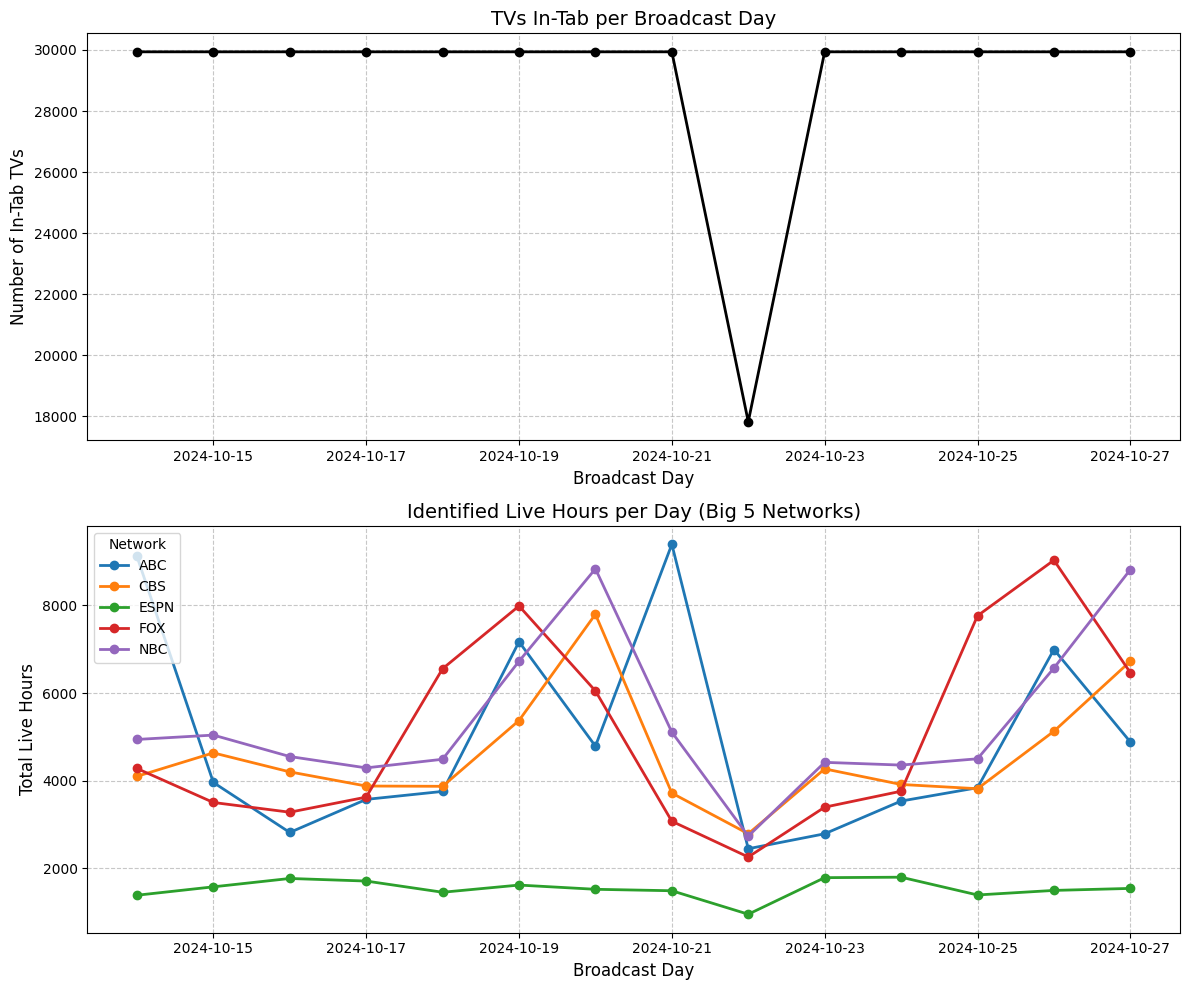

In [40]:
fig, axes = plt.subplots(2, 1, figsize=(12, 10))

in_tab_tv_days.plot(ax=axes[0], marker='o', color='black', linewidth=2)
axes[0].set_title('TVs In-Tab per Broadcast Day', fontsize=14)
axes[0].set_ylabel('Number of In-Tab TVs', fontsize=12)
axes[0].set_xlabel('Broadcast Day', fontsize=12)
axes[0].grid(True, linestyle='--', alpha=0.7)

big_five = ['ABC', 'CBS', 'NBC', 'FOX', 'ESPN']
live_big_five = valid_sessions[(valid_sessions['session_type'] == 'live') &
                               (valid_sessions['network_code'].isin(big_five))]

daily_network_hours = live_big_five.groupby(['broadcast_day', 'network_code'])['duration_hours'].sum().unstack()

daily_network_hours.plot(ax=axes[1], marker='o', linewidth=2)
axes[1].set_title('Identified Live Hours per Day (Big 5 Networks)', fontsize=14)
axes[1].set_ylabel('Total Live Hours', fontsize=12)
axes[1].set_xlabel('Broadcast Day', fontsize=12)
axes[1].legend(title='Network', fontsize=10)
axes[1].grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

## Task 4.2 — Spike and broken day

In [41]:
biggest_spike_idx = daily_network_hours.stack().idxmax()
spike_date = biggest_spike_idx[0]
spike_network = biggest_spike_idx[1]

broken_day_date = in_tab_tv_days.idxmin()

print(f"Biggest spike (date, network): {spike_date}, {spike_network}")
print(f"Broken day (date): {broken_day_date}")

Biggest spike (date, network): 2024-10-21, ABC
Broken day (date): 2024-10-22


Answer:

What aired (the spike): On October 21 (a Monday), the massive spike on ABC was driven by Monday Night Football. Real programming events move the total hours (the numerator).

What went wrong with the data: On October 22, there was a severe data collection failure or server outage at the ACR vendor. We lost contact with nearly half of the footprint, causing the number of in-tab TVs to plummet. This is a denominator problem.

Distortion: If nobody noticed, the daily total hours for October 22 would look artificially terrible. Conversely, a rating (which divides viewing by in-tab TVs) might become highly volatile or artificially inflated, depending on whether the TVs that went offline were heavy or light viewers.

Drop, fix, or flag: This day should be dropped from weekly averages and strictly flagged. The sample size is compromised, so extrapolating totals or ratings from it will be inaccurate.

## Task 5.1 — Sampling error vs bias

In [42]:
shows = ['Sunday Night Football', 'Hannity', 'Unsellable Houses']
t5_df = targets[targets['program_name'].isin(shows)].copy()

def get_panel_n(b_date):
    return dw_h[dw_h['broadcast_date'] == b_date]['respondent_id'].nunique()

t5_df['panel_n'] = t5_df['broadcast_day'].apply(get_panel_n)

t5_df['tv_n'] = t5_df['in_tab_tvs']
t5_df['p'] = t5_df['hh_rating'] / 100

t5_df['se_footprint'] = np.sqrt(t5_df['p'] * (1 - t5_df['p']) / t5_df['tv_n']) * 100
t5_df['se_panel'] = np.sqrt(t5_df['p'] * (1 - t5_df['p']) / t5_df['panel_n']) * 100

t5_df['bias'] = t5_df['tv_hh_rating'] - t5_df['hh_rating']

res5 = t5_df[['program_name', 'se_footprint', 'se_panel', 'bias']].copy()
res5['se_footprint'] = res5['se_footprint'].round(3)
res5['se_panel'] = res5['se_panel'].round(3)
res5['bias'] = res5['bias'].round(2)

print("Sampling error vs bias")
print(res5.to_string(index=False))

Sampling error vs bias
     program_name  se_footprint  se_panel  bias
          Hannity         0.087     0.241 -1.35
Unsellable Houses         0.109     0.303 -3.40


The footprint's sampling error (se_footprint) is significantly smaller than the panel's sampling error (se_panel) because of its massive sample size. However, the bias (the gap between the TVs' rating and the reference) is far bigger than either sampling error. More data (a larger $n$) shrinks the sampling error, but it does not shrink the bias caused by the unrepresentative nature of the smart TV sample.

## Task 5.2 — Answer to the planner

Answer:
For the client presentation tomorrow, the raw, unadjusted household rating from this Smart TV feed for Sunday Night Football is 6.3. However, you must caveat that this number is strictly a raw footprint measurement, not a true US rating. This ACR feed cannot see viewing happening on other television sets in the home, viewing on unrecognized apps, or viewing by households that opted out or failed to match our IP database. Furthermore, this data heavily over-represents wealthier households, meaning it systematically misrepresents the true viewing population. Before we can safely use this feed for media planning, the raw device data must be properly modeled, calibrated, and weighted against a representative currency panel to correct for its inherent biases and project it to the full US population.

## Bonus

In [43]:
snf_target = targets[targets['program_name'] == 'NFL Football'].iloc[0]
snf_telecast_id = snf_target['telecast_id']
snf_bday = snf_target['broadcast_day']

dw_h_day = daily_weights[(daily_weights['resp_type'] == 'H') & (daily_weights['broadcast_date'] == snf_bday)]
dw_p_day = daily_weights[(daily_weights['resp_type'].isin(['R', 'L'])) & (daily_weights['broadcast_date'] == snf_bday)]

us_tv_hh = dw_h_day['weight'].sum()
a2554_attrs = attributes[attributes['attr_name'].isin(['25-34', '35-49', '50-54'])]['attr_id'].tolist()
va_a2554 = viewer_attributes[viewer_attributes['attr_id'].isin(a2554_attrs)]['respondent_id'].unique()
dw_a2554_day = dw_p_day[dw_p_day['respondent_id'].isin(va_a2554)]
us_a2554_persons = dw_a2554_day['weight'].sum()

mask_panel_snf = (viewings['network_code'] == 'NBC') & \
                 (viewings['start_ts'] <= snf_target['end_ts']) & \
                 (viewings['end_ts'] >= snf_target['start_ts'])

panel_snf_viewers = viewings[mask_panel_snf].copy()

hh_watched = panel_snf_viewers[panel_snf_viewers['resp_type'] == 'H']['respondent_id'].unique()
hh_watched_weight = dw_h_day[dw_h_day['respondent_id'].isin(hh_watched)]['weight'].sum()

p_watched = panel_snf_viewers[(panel_snf_viewers['resp_type'].isin(['R', 'L'])) &
                              (panel_snf_viewers['respondent_id'].isin(va_a2554))]['respondent_id'].unique()
p_watched_weight = dw_a2554_day[dw_a2554_day['respondent_id'].isin(p_watched)]['weight'].sum()

if hh_watched_weight > 0:
    vpvh_a2554 = p_watched_weight / hh_watched_weight
else:
    vpvh_a2554 = 0.5
a2554_rating = snf_target['tv_hh_rating'] * vpvh_a2554 * (us_tv_hh / us_a2554_persons)

print(f"VPVH A25-54: {vpvh_a2554:.2f}")
print(f"A25-54 rating (persons): {a2554_rating:.1f}")

VPVH A25-54: 0.51
A25-54 rating (persons): 3.3


Answer:
This calculation assumes that the homes in the Smart TV footprint have the exact same demographic composition and co-viewing habits (Viewers Per Viewing Household) as the general US population measured by the panel. Given that we know the footprint skews higher-income and misses certain demographics, this assumption is likely flawed.